# Brain Tumor Classification — Windows Native Version

This notebook is the Windows-native conversion of the uploaded Colab notebook.

**Environment**
- Windows (no WSL/Linux)
- TensorFlow 2.10.1
- Python 3.10
- CUDA 11.2 + cuDNN 8.1.1
- NVIDIA RTX 3050 6GB

**Dataset**
- `D:\BrainTumor\Training`
- `D:\BrainTumor\Testing`

**Classes**
- glioma
- meningioma
- notumor
- pituitary

The Experiment 2 VGG16 architecture and two-stage training strategy from the source notebook are retained.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score
import seaborn as sns

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.10.1
NumPy: 1.23.5
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
DATASET_PATH = r"D:\BrainTumor"
TRAIN_PATH = os.path.join(DATASET_PATH, "Training")
TEST_PATH = os.path.join(DATASET_PATH, "Testing")

In [3]:
import sys
import os

print("Python executable:")
print(sys.executable)

print("\nCUDA_PATH:")
print(os.environ.get("CUDA_PATH"))

print("\nCUDA_PATH_V11_2:")
print(os.environ.get("CUDA_PATH_V11_2"))

print("\nCUDA bin exists:")
print(os.path.exists(
    r"C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v11.2\bin"
))

print("\ncuDNN DLL exists:")
print(os.path.exists(
    r"C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v11.2\bin\cudnn64_8.dll"
))

print("\nCUDA runtime DLL exists:")
print(os.path.exists(
    r"C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v11.2\bin\cudart64_110.dll"
))

Python executable:
d:\BrainTumor\venv\Scripts\python.exe

CUDA_PATH:
C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v11.2

CUDA_PATH_V11_2:
C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v11.2

CUDA bin exists:
True

cuDNN DLL exists:
True

CUDA runtime DLL exists:
True


In [4]:
# Windows dataset paths
DATASET_PATH = r"D:\BrainTumor"
TRAIN_PATH = os.path.join(DATASET_PATH, "Training")
TEST_PATH = os.path.join(DATASET_PATH, "Testing")

print("Training path:", TRAIN_PATH)
print("Testing path:", TEST_PATH)

assert os.path.isdir(TRAIN_PATH), f"Training folder not found: {TRAIN_PATH}"
assert os.path.isdir(TEST_PATH), f"Testing folder not found: {TEST_PATH}"

classes = ["glioma", "meningioma", "notumor", "pituitary"]
for split_path in [TRAIN_PATH, TEST_PATH]:
    for cls in classes:
        class_path = os.path.join(split_path, cls)
        assert os.path.isdir(class_path), f"Missing class folder: {class_path}"

print("Dataset structure verified.")


Training path: D:\BrainTumor\Training
Testing path: D:\BrainTumor\Testing
Dataset structure verified.


In [5]:
# Experiment 2 data generators
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

# VGG16 expects ImageNet preprocessing (RGB to BGR and channel centering).
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    validation_split=0.20
)

# Validation must not use random augmentation; it is used to select the model and threshold.
validation_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.20
)

test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    shuffle=True,
    seed=42
)

validation_generator = validation_datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    shuffle=False,
    seed=42
)

test_generator = test_datagen.flow_from_directory(
    TEST_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False 
)

print("Class indices:", train_generator.class_indices)


Found 4480 images belonging to 4 classes.
Found 1120 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.
Class indices: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [6]:
# Experiment 2 — VGG16 base initially frozen
# VGG16 transfer-learning base initially frozen.
base_model_exp2 = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model_exp2.trainable = False

x = base_model_exp2.output
x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation="relu")(x)
x = Dense(1024, activation="relu")(x)
x = Dense(512, activation="relu")(x)
x = Dropout(0.2)(x)
output = Dense(4, activation="softmax")(x)

model_exp2 = Model(inputs=base_model_exp2.input, outputs=output, name="vgg16_brain_tumor")

# Raise the cost of missing glioma while keeping the other classes at normal weight.
glioma_class_weights = tf.constant([2.5, 1.0, 1.0, 1.0], dtype=tf.float32)

def glioma_weighted_cce(y_true, y_pred):
    base_loss = tf.keras.losses.categorical_crossentropy(y_true, y_pred)
    sample_weight = tf.reduce_sum(y_true * glioma_class_weights, axis=-1)
    return base_loss * sample_weight

class GliomaRecallCallback(tf.keras.callbacks.Callback):
    def __init__(self, validation_generator):
        super().__init__()
        self.validation_generator = validation_generator

    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        self.validation_generator.reset()
        probabilities = self.model.predict(self.validation_generator, verbose=0)
        predictions = np.argmax(probabilities, axis=1)
        true_labels = self.validation_generator.classes
        glioma_recall = recall_score(true_labels == 0, predictions == 0)
        logs["val_glioma_recall"] = glioma_recall
        print(f"glioma validation recall: {glioma_recall:.4f}")

model_exp2.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss=glioma_weighted_cce,
    metrics=["accuracy"]
)

model_exp2.summary()


Model: "vgg16_brain_tumor"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 block1_conv1 (Conv2D)       (None, 224, 224, 64)      1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 224, 224, 64)      36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 112, 112, 64)      0         
                                                                 
 block2_conv1 (Conv2D)       (None, 112, 112, 128)     73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 112, 112, 128)     147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 56, 56, 128) 

In [8]:
# Stage 1 — train classification head with VGG16 frozen
stage1_checkpoint = os.path.join(
    DATASET_PATH,
    "vgg16_brain_tumor_stage1_best.weights.h5"
)

stage1_callbacks = [
    GliomaRecallCallback(validation_generator),
    EarlyStopping(
        monitor="val_glioma_recall",
        mode="max",
        patience=6,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        stage1_checkpoint,
        monitor="val_glioma_recall",
        mode="max",
        save_best_only=True,
        save_weights_only=True
    )
]

history_stage1 = model_exp2.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=10,
    callbacks=stage1_callbacks
)


Epoch 1/10
280/280 [==============================] - 52s 183ms/step - loss: 0.2304 - accuracy: 0.9306 - val_loss: 0.3443 - val_accuracy: 0.9107 - val_glioma_recall: 0.8821
Epoch 2/10
280/280 [==============================] - 52s 187ms/step - loss: 0.1995 - accuracy: 0.9388 - val_loss: 0.2729 - val_accuracy: 0.9286 - val_glioma_recall: 0.9607
Epoch 3/10
280/280 [==============================] - 50s 179ms/step - loss: 0.1931 - accuracy: 0.9400 - val_loss: 0.2914 - val_accuracy: 0.8973 - val_glioma_recall: 0.9857
Epoch 4/10
280/280 [==============================] - 45s 161ms/step - loss: 0.1514 - accuracy: 0.9527 - val_loss: 0.3205 - val_accuracy: 0.8946 - val_glioma_recall: 0.9786
Epoch 5/10
280/280 [==============================] - 40s 142ms/step - loss: 0.1381 - accuracy: 0.9571 - val_loss: 0.2884 - val_accuracy: 0.9339 - val_glioma_recall: 0.9321
Epoch 6/10
280/280 [==============================] - 46s 165ms/step - loss: 0.1238 - accuracy: 0.9629 - val_loss: 0.2734 - val_accurac

In [10]:
# Stage 2 — fine-tune VGG16 Block 4 + Block 5
# Keep earlier VGG16 blocks the convolution layer unfrozen the dense layer.

base_model_exp2.trainable = True

for layer in base_model_exp2.layers:
    layer.trainable = False


for layer in base_model_exp2.layers:
    if layer.name.startswith("block4_") or layer.name.startswith("block5_"):
        layer.trainable = True

#.
# Class indices: glioma=0, meningioma=1, notumor=2, pituitary=3.
glioma_class_weights = tf.constant([2.5, 1.0, 1.0, 1.0], dtype=tf.float32)

def glioma_weighted_cce(y_true, y_pred):
    base_loss = tf.keras.losses.categorical_crossentropy(y_true, y_pred)
    sample_weight = tf.reduce_sum(y_true * glioma_class_weights, axis=-1)
    return base_loss * sample_weight

class GliomaRecallCallback(tf.keras.callbacks.Callback):
    def __init__(self, validation_generator):
        super().__init__()
        self.validation_generator = validation_generator

    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        self.validation_generator.reset()
        probabilities = self.model.predict(self.validation_generator, verbose=0)
        predictions = np.argmax(probabilities, axis=1)
        true_labels = self.validation_generator.classes
        glioma_recall = recall_score(true_labels == 0, predictions == 0)
        logs["val_glioma_recall"] = glioma_recall
        print(f" — val_glioma_recall: {glioma_recall:.4f}")

model_exp2.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss=glioma_weighted_cce,
    metrics=["accuracy"]
)

stage2_checkpoint = os.path.join(
    DATASET_PATH,
    "vgg16_brain_tumor_best_glioma_recall.weights.h5"
)

stage2_callbacks = [
    GliomaRecallCallback(validation_generator),
    EarlyStopping(
        monitor="val_glioma_recall",
        mode="max",
        patience=6,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        stage2_checkpoint,
        monitor="val_glioma_recall",
        mode="max",
        save_best_only=True,
        save_weights_only=True
    )
]

history_stage2 = model_exp2.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=10,
    callbacks=stage2_callbacks
)


Epoch 1/10
280/280 [==============================] - 55s 195ms/step - loss: 0.1789 - accuracy: 0.9438 - val_loss: 0.2265 - val_accuracy: 0.9580 - val_glioma_recall: 0.9500
Epoch 2/10
280/280 [==============================] - 55s 198ms/step - loss: 0.1020 - accuracy: 0.9688 - val_loss: 0.2371 - val_accuracy: 0.9214 - val_glioma_recall: 0.9929
Epoch 3/10
280/280 [==============================] - 55s 196ms/step - loss: 0.0809 - accuracy: 0.9781 - val_loss: 0.2050 - val_accuracy: 0.9429 - val_glioma_recall: 0.9679
Epoch 4/10
280/280 [==============================] - 55s 198ms/step - loss: 0.0674 - accuracy: 0.9824 - val_loss: 0.1783 - val_accuracy: 0.9554 - val_glioma_recall: 0.9643
Epoch 5/10
280/280 [==============================] - 55s 197ms/step - loss: 0.0560 - accuracy: 0.9828 - val_loss: 0.1408 - val_accuracy: 0.9705 - val_glioma_recall: 0.9821
Epoch 6/10
280/280 [==============================] - 55s 195ms/step - loss: 0.0409 - accuracy: 0.9888 - val_loss: 0.1153 - val_accurac

In [11]:
# Save the final Experiment 2 model locally
final_model_path = os.path.join(
    DATASET_PATH,
    "vgg16_brain_tumor_best_glioma_recall.weights.h5"
)

model_exp2.save_weights(final_model_path)
print("Saved model:", final_model_path)


Saved model: D:\BrainTumor\vgg16_brain_tumor_best_glioma_recall.weights.h5


In [12]:
# Tune the glioma decision threshold on validation data only.
# Do not use the Testing directory for threshold selection.
GLIOMA_INDEX = train_generator.class_indices["glioma"]
TARGET_GLIOMA_RECALL = 0.95

validation_generator.reset()
validation_probabilities = model_exp2.predict(validation_generator, verbose=1)
validation_true = validation_generator.classes

threshold_candidates = np.arange(0.01, 1.00, 0.005)
valid_thresholds = []

for threshold in threshold_candidates:
    validation_pred = np.argmax(validation_probabilities, axis=1)
    validation_pred[validation_probabilities[:, GLIOMA_INDEX] >= threshold] = GLIOMA_INDEX

    glioma_recall = recall_score(validation_true == GLIOMA_INDEX, validation_pred == GLIOMA_INDEX)
    glioma_precision = precision_score(
        validation_true == GLIOMA_INDEX, validation_pred == GLIOMA_INDEX, zero_division=0
    )

    if glioma_recall >= TARGET_GLIOMA_RECALL:
        valid_thresholds.append((glioma_precision, threshold, glioma_recall))

if not valid_thresholds:
    raise RuntimeError(
        "No validation threshold reached 95% glioma recall. Increase glioma_class_weights "
        "to 3.0 and retrain Stage 2."
    )

# Among thresholds reaching the target, keep the one with highest precision.
best_precision, GLIOMA_THRESHOLD, validation_glioma_recall = max(valid_thresholds)
print(f"Chosen glioma threshold: {GLIOMA_THRESHOLD:.3f}")
print(f"Validation glioma recall: {validation_glioma_recall:.3%}")
print(f"Validation glioma precision: {best_precision:.3%}")


70/70 [==============================] - 6s 85ms/step
Chosen glioma threshold: 0.995
Validation glioma recall: 99.286%
Validation glioma precision: 82.738%


100/100 [==============================] - 14s 137ms/step
              precision    recall  f1-score   support

      glioma       0.85      0.83      0.84       400
  meningioma       0.92      0.82      0.87       400
     notumor       0.88      1.00      0.94       400
   pituitary       0.96      0.96      0.96       400

    accuracy                           0.90      1600
   macro avg       0.90      0.90      0.90      1600
weighted avg       0.90      0.90      0.90      1600



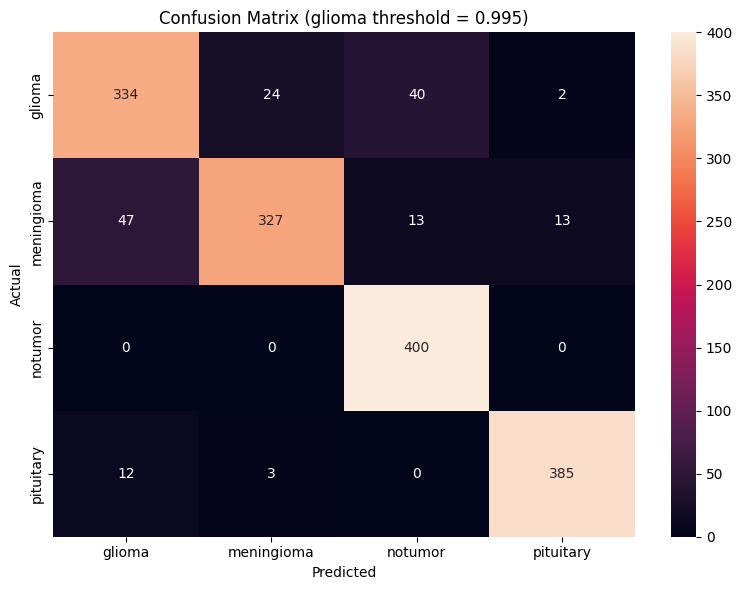

In [13]:
# Final independent test evaluation using the validation-selected glioma threshold
test_generator.reset()
predictions = model_exp2.predict(test_generator, verbose=1)
y_pred = np.argmax(predictions, axis=1)
y_pred[predictions[:, GLIOMA_INDEX] >= GLIOMA_THRESHOLD] = GLIOMA_INDEX
y_true = test_generator.classes

class_names = list(test_generator.class_indices.keys())

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix (glioma threshold = {GLIOMA_THRESHOLD:.3f})")
plt.tight_layout()
plt.show()


In [14]:
print("model_exp2 exists:", "model_exp2" in globals())
print("IMG_SIZE exists:", "IMG_SIZE" in globals())
print("class_names exists:", "class_names" in globals())
print("DATASET_PATH exists:", "DATASET_PATH" in globals())

model_exp2 exists: True
IMG_SIZE exists: True
class_names exists: True
DATASET_PATH exists: True


## Windows image prediction

The next cell lets you provide an image from any Windows folder by entering its full path.

Example:

`D:\MRI\patient1.jpg`

It does not require Google Colab file upload.


In [1]:
import os
import ipywidgets as widgets
from IPython.display import display, clear_output

upload = widgets.FileUpload(
    accept="image/*",
    multiple=False,
    description="Upload MRI Image"
)

prediction_output = widgets.Output()

display(upload)
display(prediction_output)


def predict_brain_tumor(image_path, model=model_exp2):
    """Load one MRI image and display the model's predicted class."""
    image = tf.keras.utils.load_img(image_path, target_size=IMG_SIZE)
    image_array = tf.keras.utils.img_to_array(image)
    image_batch = np.expand_dims(image_array, axis=0)
    probabilities = model.predict(preprocess_input(image_batch), verbose=0)[0]

    predicted_index = int(np.argmax(probabilities))
    predicted_class = class_names[predicted_index]
    confidence = float(probabilities[predicted_index])

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Prediction: {predicted_class} ({confidence:.2%})")
    plt.show()

    print(f"Prediction: {predicted_class}")
    print(f"Confidence: {confidence:.2%}")
    print("Class probabilities:")
    for name, probability in zip(class_names, probabilities):
        print(f"  {name}: {probability:.2%}")

    return predicted_class, probabilities


def handle_upload(change):

    if not upload.value:
        return

    with prediction_output:

        clear_output(wait=True)

        # ipywidgets 7 returns a dict; ipywidgets 8 returns a tuple.
        uploaded_files = upload.value
        uploaded_file = (
            next(iter(uploaded_files.values()))
            if isinstance(uploaded_files, dict)
            else uploaded_files[0]
        )

        file_name = uploaded_file["name"]
        file_content = uploaded_file["content"]

        upload_dir = os.path.join(
            DATASET_PATH,
            "uploaded_images"
        )

        os.makedirs(upload_dir, exist_ok=True)

        image_path = os.path.join(
            upload_dir,
            file_name
        )

        with open(image_path, "wb") as f:
            f.write(bytes(file_content))

        print(f"Uploaded image: {file_name}")
        print("\nRunning prediction...\n")

        predict_brain_tumor(
            image_path,
            model=model_exp2
        )


upload.observe(handle_upload, names="value")

FileUpload(value=(), accept='image/*', description='Upload MRI Image')

Output()

NameError: name 'model_exp2' is not defined